# IQR(Inter Quartile Range) method to deal with outliers is only applicable to data having `skewed distribution`.

* This method is based on the **box plot**.
* **Box plot** is a five number summary which gives us five informations on any column. They are, 1)  25th Percentile(Q1),
2) 75th Percentile(Q3), 3) Median, 4) Lower limit and 5) Upper limit.
* **Lower Limit** = Q1 - 1.5(IQR)
* **Upper limit** = Q3 + 1.5(IQR)
* IQR stands for **Inter Quartile Range** = Q3 - Q1

* `All those data points which falls outside this **lower limit** and **upper limit** are considered as outliers.`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("00 placement.csv")

In [3]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [8]:
df.shape

(1000, 3)

C:\Users\jugal\AppData\Local\Temp\ipykernel_11208\1920317787.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_11208\1920317787.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df.placement_exam_marks)


Text(0.5, 1.0, 'Placement_exam_marks')

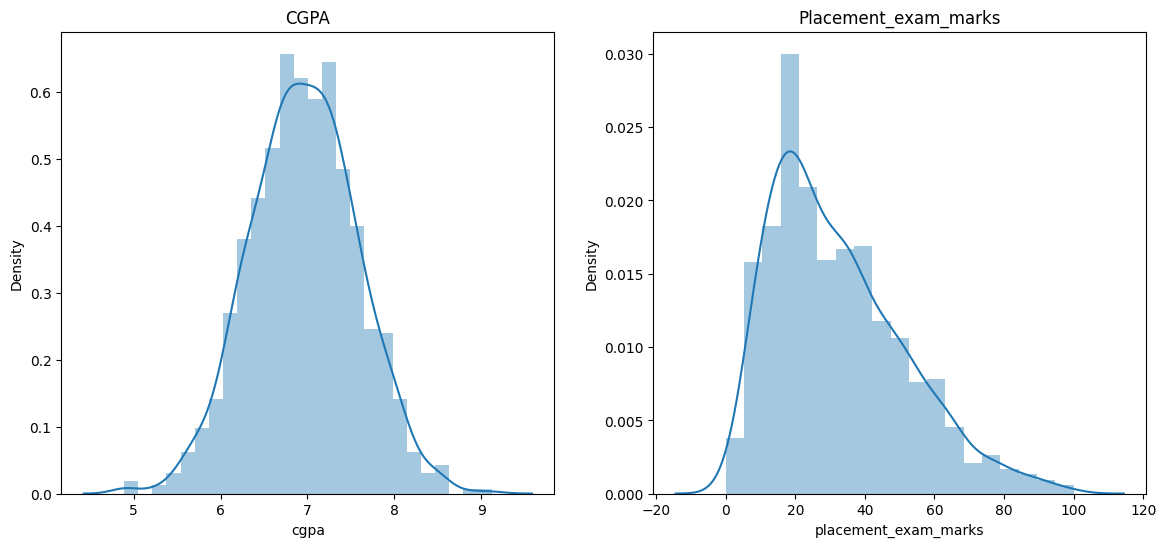

In [6]:
# Let's find which column had skewed distribution.

plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.distplot(df['cgpa'])
plt.title('CGPA')

plt.subplot(122)
sns.distplot(df.placement_exam_marks)
plt.title('Placement_exam_marks')

In [7]:
# We can see that column 'placement _exam_marks' is somewhat left skewed. So we will apply our IQR method on this column.

In [10]:
df.placement_exam_marks.describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<AxesSubplot: ylabel='placement_exam_marks'>

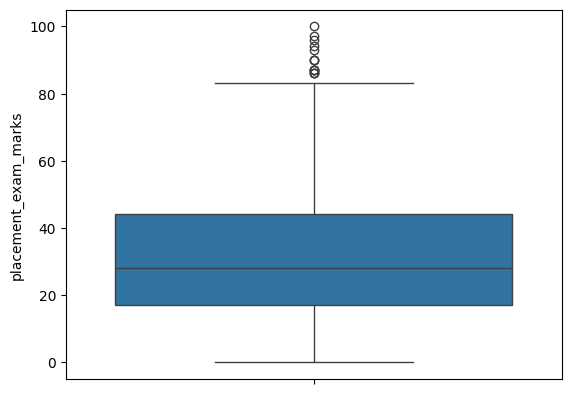

In [11]:
# Let's create a box-plot and see how many outliers are present.

sns.boxplot(df.placement_exam_marks)

<AxesSubplot: xlabel='placement_exam_marks'>

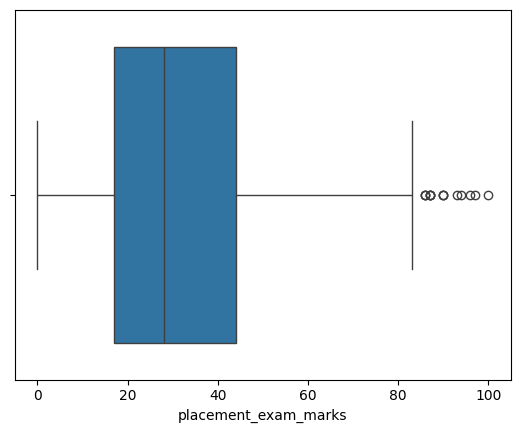

In [14]:
sns.boxplot(df['placement_exam_marks'], orient = 'h')

# Finding lower limit and upper limit.

In [15]:
q3 = df['placement_exam_marks'].quantile(0.75)
q1 =df['placement_exam_marks'].quantile(0.25)

In [17]:
print(f'25th percentile Q1: {q1}')
print(f'75th percentile Q3: {q3}')

# We can see we are getting the same result as we got when we used describe() function above.

25th percentile Q1: 17.0
75th percentile Q3: 44.0


In [19]:
iqr = q3 - q1

print(f'Inter Quartile Range IQR: {iqr}')

Inter Quartile Range IQR: 27.0


In [27]:
lower_limit = q1 - (1.5* iqr)
upper_limit = q3 + (1.5* iqr)

In [28]:
print(f'Upper limit: {upper_limit}')
print(f'Lower limit: {lower_limit}')

Upper limit: 84.5
Lower limit: -23.5


In [29]:
# Hence the marks above 84.5 and -23.5 are outliers. Here lower_limit is -23.5 so there'll be no outliers on lower side bcz our
# minimun marks is zero.

# Finding outliers.

In [30]:
outliers = df[
(df.placement_exam_marks < lower_limit) |
(df.placement_exam_marks > upper_limit)
]

In [34]:
outliers

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [32]:
# There will be no outliers on the side of lower limit.
df[
(df['placement_exam_marks'] < lower_limit)
]

,cgpa,placement_exam_marks,placed


# Dealing with outliers. 1) Trimming and 2) Capping

# 1) Trimming

In [ ]:
# All those values which are higher than lower limit and lower than upper limit are valid points. They are not outliers.

trimed_df = df[
(df.placement_exam_marks > lower_limit) &
(df.placement_exam_marks < upper_limit)
]

In [47]:
trimed_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


C:\Users\jugal\AppData\Local\Temp\ipykernel_11208\772178852.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df.placement_exam_marks)
C:\Users\jugal\AppData\Local\Temp\ipykernel_11208\772178852.py:14: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(trimed_df.placement_exam_marks)


Text(0.5, 1.0, 'trimed data')

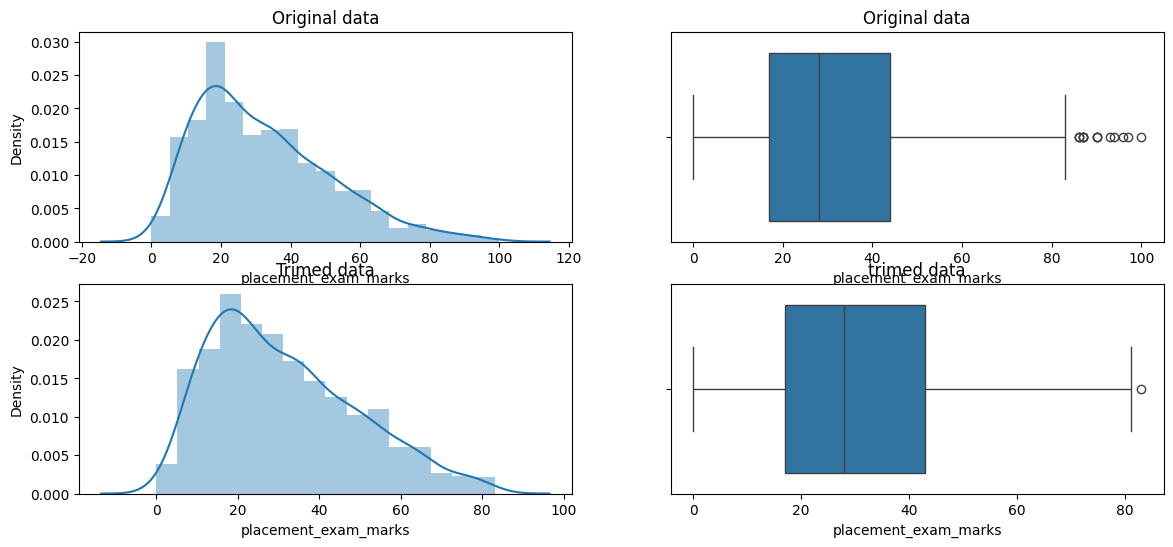

In [53]:
# Let' see the changes on graph.

plt.figure(figsize = (14, 6))

plt.subplot(221)
sns.distplot(df.placement_exam_marks)
plt.title('Original data')

plt.subplot(222)
sns.boxplot(df.placement_exam_marks, orient = 'h')
plt.title('Original data')

plt.subplot(223)
sns.distplot(trimed_df.placement_exam_marks)
plt.title('Trimed data')

plt.subplot(224)
sns.boxplot(trimed_df.placement_exam_marks, orient = 'h')
plt.title('trimed data')


# 3) Capping

In [64]:
capped_df = df.copy()

In [65]:
capped_df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [66]:
capped_df['placement_exam_marks'] = np.where(df['placement_exam_marks'] < lower_limit, lower_limit,
                    np.where(df['placement_exam_marks'] > upper_limit, upper_limit, df['placement_exam_marks']))

In [67]:
capped_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [75]:
df.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961240,32.225000,0.489000
std,0.615898,19.130822,0.500129
min,4.890000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,9.120000,100.000000,1.000000


In [76]:
capped_df.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961240,32.136500,0.489000
std,0.615898,18.865419,0.500129
min,4.890000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,9.120000,84.500000,1.000000


In [77]:
# We can see maximum marks changed from 100 to 84.5, and minimum marks in the dataset was 0 which is already less than lower_limit
# So capping is done


In [80]:
capped_df[
(capped_df['placement_exam_marks'] < lower_limit) |
(capped_df['placement_exam_marks'] > upper_limit)
]

,cgpa,placement_exam_marks,placed
